<a href="https://colab.research.google.com/github/yazanhabayeb123-hash/Student-Performance-EDA/blob/main/Student_Performance_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy import stats

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
# Student Performance in Exams
#Author: Yazan Habayeb

df = pd.read_csv('/content/StudentsPerformance.csv')
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [52]:

## Project Overview
#A school wants to understand which factors are related to student exam performance so it can decide where to focus its support for students.   This end-to-end exploratory data analysis (EDA) project progresses from data understanding and cleaning to statistical analysis, visualization, and actionable recommendations for school administrators.   Stakeholder: School administrators and teachers
#Main Feature to Analyze: math_score (along with reading and writing scores)
#Tools Used: Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Google Colab, GitHub


In [53]:
## Load and Inspect Data
print("\n--- Dataset Info ---")
df.info()
print("\n--- Summary Statistics ---")
display(df.describe())


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- Summary Statistics ---


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [54]:
## Clean Data
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
for col in ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']:
    print(f"Unique {col}: {df[col].unique()}")
df = df.rename(columns={
    'race/ethnicity': 'race_ethnicity',
    'parental level of education': 'parental_level_of_education',
    'test preparation course': 'test_preparation_course',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
})

print("\nRenamed columns:", df.columns.tolist())

Missing values:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Duplicate rows: 0
Unique gender: ['female' 'male']
Unique race/ethnicity: ['group B' 'group C' 'group A' 'group D' 'group E']
Unique parental level of education: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Unique lunch: ['standard' 'free/reduced']
Unique test preparation course: ['none' 'completed']

Renamed columns: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


In [55]:
## Data Preparation
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average_score'] = df['total_score'] / 3
df[['math_score', 'reading_score', 'writing_score', 'total_score', 'average_score']].head()

,math_score,reading_score,writing_score,total_score,average_score
0,72,72,74,218,72.666667
1,69,90,88,247,82.333333
2,90,95,93,278,92.666667
3,47,57,44,148,49.333333
4,76,78,75,229,76.333333


In [56]:
## Statistical Analysis: Math Score
# Shapiro-Wilk Test for Normality on Math Score
stat, p_val = stats.shapiro(df['math_score'])
print(f"Shapiro-Wilk Statistic: {stat:.4f}, p-value: {p_val:.5f}")
if p_val > 0.05:
    print("Conclusion: Math scores follow a normal distribution (fail to reject H0).")
else:
    print("Conclusion: Math scores do NOT strictly follow a normal distribution (reject H0).")

Shapiro-Wilk Statistic: 0.9932, p-value: 0.00015
Conclusion: Math scores do NOT strictly follow a normal distribution (reject H0).


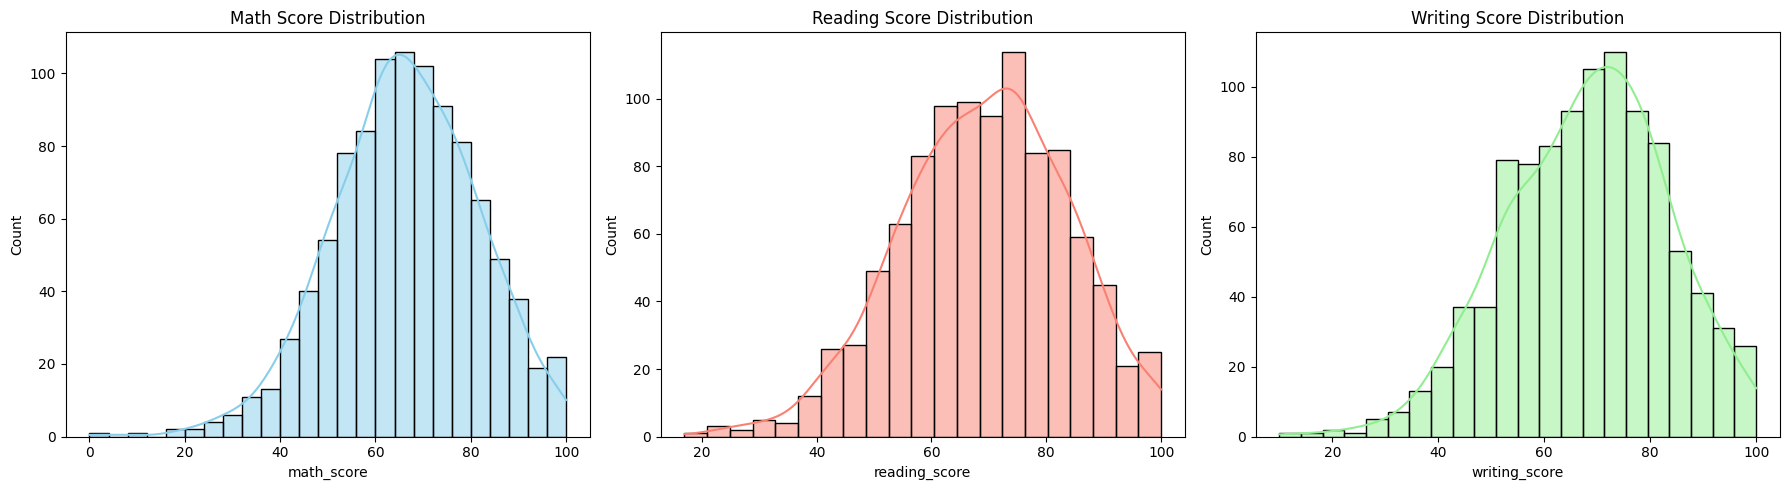

--- Score Variability Summary ---


,Mean,Std Dev,CV
math_score,66.089,15.163080,0.229434
reading_score,69.169,14.600192,0.211080
writing_score,68.054,15.195657,0.223288


In [57]:
## Univariate Analysis
# Visualize distributions of all three exam scores
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['math_score'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Math Score Distribution')

sns.histplot(df['reading_score'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Reading Score Distribution')

sns.histplot(df['writing_score'], kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Writing Score Distribution')

plt.tight_layout()
plt.show()

# Calculate Summary Statistics & Coefficient of Variation (CV)
stats_summary = pd.DataFrame({
    'Mean': df[['math_score', 'reading_score', 'writing_score']].mean(),
    'Std Dev': df[['math_score', 'reading_score', 'writing_score']].std(),
    'CV': df[['math_score', 'reading_score', 'writing_score']].std() / df[['math_score', 'reading_score', 'writing_score']].mean()
})
print("--- Score Variability Summary ---")
display(stats_summary)

/tmp/ipykernel_2717/1180156320.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='test_preparation_course', y='math_score', data=df, palette='Set2')


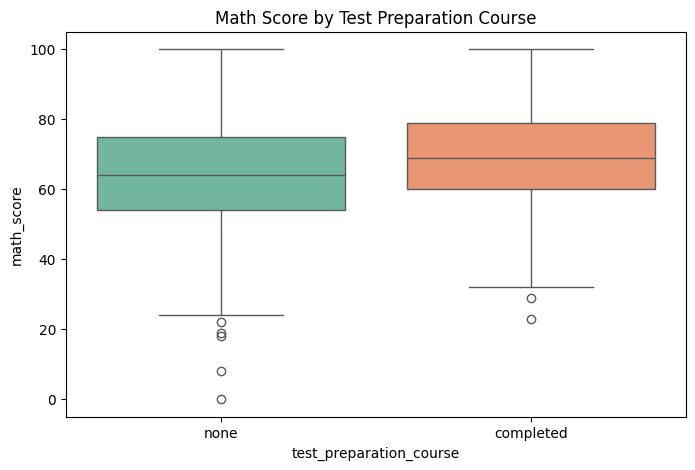

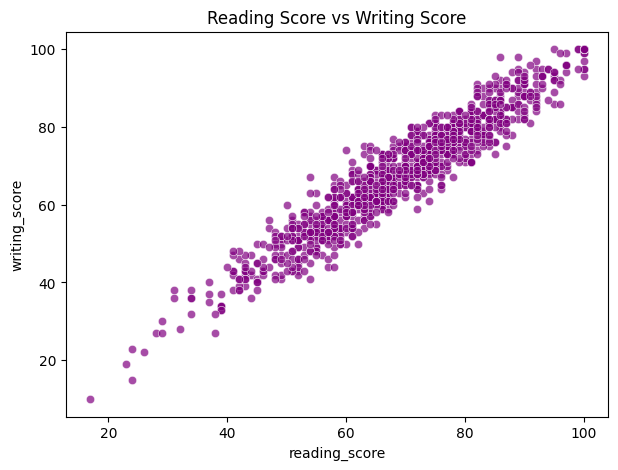

Pearson Correlation (Reading & Writing): 0.9546


/tmp/ipykernel_2717/1180156320.py:19: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='parental_level_of_education', y='average_score', data=df, ci=None, palette='Blues_d')
/tmp/ipykernel_2717/1180156320.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='parental_level_of_education', y='average_score', data=df, ci=None, palette='Blues_d')


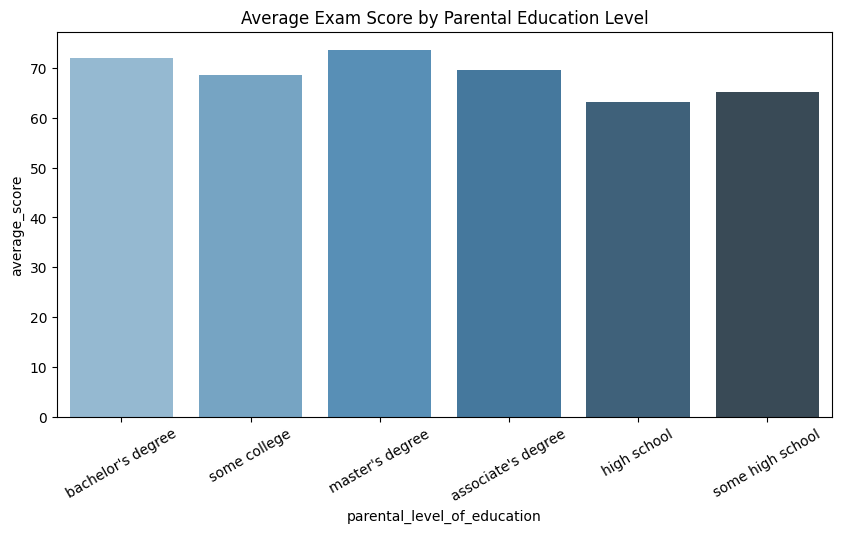

In [58]:
## Multivariate Analysis
# 1. Test Preparation vs Math Score
plt.figure(figsize=(8, 5))
sns.boxplot(x='test_preparation_course', y='math_score', data=df, palette='Set2')
plt.title('Math Score by Test Preparation Course')
plt.show()

# 2. Reading vs Writing Score Correlation
plt.figure(figsize=(7, 5))
sns.scatterplot(x='reading_score', y='writing_score', data=df, alpha=0.7, color='purple')
plt.title('Reading Score vs Writing Score')
plt.show()

corr = df['reading_score'].corr(df['writing_score'])
print(f"Pearson Correlation (Reading & Writing): {corr:.4f}")

# 3. Parental Education vs Average Score
plt.figure(figsize=(10, 5))
sns.barplot(x='parental_level_of_education', y='average_score', data=df, ci=None, palette='Blues_d')
plt.xticks(rotation=30)
plt.title('Average Exam Score by Parental Education Level')
plt.show()

In [59]:
## Conclusions

#1. **Normality:** Math scores deviate slightly from a strict normal distribution based on the Shapiro-Wilk test ($p < 0.05$).
#2. **Test Preparation:** Completing a test preparation course has a clear, positive impact on student performance across all exams.
#3. **Correlations:** Reading and writing scores show a near-perfect positive correlation ($r \approx 0.955$).
#4. **Variability:** Math scores display the highest relative dispersion (Coefficient of Variation of $0.229$).
#5. **Parental Influence:** Students whose parents hold higher educational degrees (Bachelor's or Master's) consistently achieve higher average scores.

#**Recommendation for Stakeholders:** School administrators should invest in expanding test preparation programs and providing targeted support for students to bridge achievement gaps associated with parental educational backgrounds.